In [1]:
import yaml
import warnings

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
import PyComplexHeatmap as pch
from pathlib import Path
from tqdm.auto import tqdm

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
# matplotlib.rcParams['font.family'] = 'Arial'

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']

Results to assemble:
- BAGEL2 results
- MAGeCK results
- Gscreend results
- L2FC results
- Specificity
    - cell line wise
    - gene / transcript wise

# Counts

In [166]:
# Get counts
counts = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

In [167]:
counts

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP3,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
AATBC_ENST00000400385_1005,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0983:983-1005,ACAGAACCCTAGGAAGCAACCTC,1005.0,0.789626,Gene_Body,4598.0,...,1494,1747,1655,1494,1545,1298,1388,1842,1277,1391
AATBC_ENST00000400385_1562,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1504:1540-1562,CCAGGCCACTTGCTCCACCCTCT,1562.0,0.747814,Gene_Body,4598.0,...,2072,2450,2161,2318,2164,1774,2055,2276,1863,2168
AATBC_ENST00000400385_1938,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1862:1916-1938,TGACCTCTCACCCCGCAGCCTCT,1938.0,0.747682,Gene_Body,4598.0,...,1299,1680,1402,1473,1463,1166,1192,1650,1139,1391
AATBC_ENST00000400385_2713,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA2601:2691-2713,CTGCCTTATAAAGATAGACCGGT,2713.0,0.870540,Gene_Body,4598.0,...,1175,1268,1071,1026,1157,892,976,1263,835,1073
AATBC_ENST00000400385_28,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0006:6-28,CCGGTCTCTGCAGTCACCCTCCT,28.0,0.762563,Gene_Body,4598.0,...,1898,2201,1797,1975,2039,1678,1794,2248,1576,1842
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RPS16_ENST00000251453_280,ENST00000251453,ENSG00000105193,RPS16,protein_coding,crRNA258:258-280,CCACCACCCTTTACACGGACACG,280.0,0.891826,CDS,631.0,...,337,335,275,171,1198,468,334,230,156,154
RPS16_ENST00000251453_300,ENST00000251453,ENSG00000105193,RPS16,protein_coding,crRNA278:278-300,CATAAATCTGGGCCACGTGACCA,300.0,0.892320,CDS,631.0,...,187,155,153,117,901,319,163,106,88,93
RPS5_ENST00000196551_431,ENST00000196551,ENSG00000083845,RPS5,protein_coding,crRNA409:409-431,CCACTGTTGATGATGGCGTTCAC,431.0,1.006859,CDS,741.0,...,865,787,762,652,1532,864,758,669,475,478


# BAGEL

In [379]:
filtered = True
time = 'TP5TP6'
name = '_filtered' if filtered else ''
# get data
df = pd.read_table(f'../results/bagel2/pooled_screen_1_counts{name}_bagel_pr_gene.tsv', index_col=0, header=[0,1,2])

bagel_df = df.loc[:, ('alllines', time)].drop(['Recall', 'Precision'], axis=1).rename({'BF': 'Bayesfactor'}, axis=1)
bagel_df.columns = ['Bagel2_' + x for x in bagel_df.columns]
bagel_df


,Bagel2_Bayesfactor,Bagel2_FDR
Gene,,
RAN,4046.935,0.000
FBL,2315.745,0.000
EIF4A1,1694.624,0.000
MYC,1553.625,0.000
GAS5,1620.207,0.000
...,...,...
LSM11,-125.621,0.077
ASB17,-133.002,0.082
PCBP4,-173.646,0.082


In [236]:
# specificity per line (disfunct)
# sdf = df.loc[:, (cell_line_dict.values(), time)]
# sdf.columns = sdf.columns.droplevel(1)
# spec = sdf.loc[:, (slice(None), 'FDR')].var(axis=1).sort_values(ascending=False)
# spec.head(20)

# sdf = df.loc[:, (cell_line_dict.values(), time)]
# sdf.columns = sdf.columns.droplevel(1)
# spec = (sdf.loc[:, (slice(None), 'BF')].var(axis=1)/ sdf.loc[:, (slice(None), 'BF')].abs().mean(axis=1)).sort_values(ascending=False)
# spec.head(20)

# MAGeCK

## Guide-wise

In [221]:
# There are three types of MAGeCK output: gene, transcript, and guide wise results

filtered = False
name = '_filtered' if filtered else ''

In [233]:
guide_ranking = pd.read_csv(f'../results/mageck/alllines/pooled_screen_1_counts_mageck.sgrna_summary.txt', sep='\t', index_col=0)
# remove columns that are confusing
guide_ranking = guide_ranking.drop(['control_count', 'treatment_count', 'control_mean', 'treat_mean', 'LFC', 'control_var', 'adj_var', 'p.low', 'p.high', 'high_in_treatment'], axis=1)
guide_ranking.rename({'score': 'MAGeCK_score', 'p.twosided': 'MAGeCK_pval', 'FDR': 'MAGeCK_FDR'}, axis=1)

# specificity of guides w.r.t. cell lines
guide_rankings = pd.concat({cell_line: pd.read_csv(f'../results/mageck/{cell_line}/pooled_screen_1_counts_mageck.sgrna_summary.txt', sep='\t', index_col=0).drop(
    ['control_count', 'treatment_count', 'control_mean', 'treat_mean', 'LFC', 'control_var', 'adj_var', 'p.low', 'p.high', 'high_in_treatment', 'Gene'], axis=1)
                  for cell_line in cell_line_dict.values()}, axis=1)
spec = guide_rankings.loc[:, (slice(None), 'FDR')].var(axis=1)
guide_ranking['MAGeCK_cell_line_specificity'] = spec

# Rename
guide_ranking = guide_ranking.rename({'score': 'MAGeCK_score', 'p.twosided': 'MAGeCK_pval', 'FDR': 'MAGeCK_FDR'}, axis=1)

In [234]:
guide_ranking

,Gene,MAGeCK_score,MAGeCK_pval,MAGeCK_FDR,MAGeCK_cell_line_specificity
sgrna,,,,,
RPL10_ENST00000436473_467,RPL10,27.158000,1.996000e-162,1.242500e-158,5.354343e-113
RAN_ENST00000535090_324,RAN,26.162000,7.218600e-151,2.246800e-147,2.377042e-107
ACTG1_ENST00000573283_1731,ACTG1,25.906000,5.726500e-148,1.188200e-144,8.699468e-109
RPL14_ENST00000416518_279,RPL14,25.654000,2.311100e-145,3.596700e-142,1.095423e-105
CCT8_ENST00000286788_1903,CCT8,25.436000,1.019500e-142,1.269300e-139,3.374829e-104
...,...,...,...,...,...
UBE2I_ENST00000397514_282,UBE2I,0.007003,9.944100e-01,9.950500e-01,2.942749e-01
SRRM1_ENST00000323848_574,SRRM1,0.005092,9.959400e-01,9.964200e-01,2.679215e-01
UBE2D3_ENST00000394803_368,UBE2D3,0.002355,9.981200e-01,9.984400e-01,3.231938e-01


## Gene-wise

In [380]:
filtered = True
time = 'TP5TP6'
name = '_filtered' if filtered else ''

gene_ranking = pd.read_csv(f'../results/mageck/alllines/gene_pooled_screen_1_counts{name}_mageck.gene_summary.txt', sep='\t', index_col=0)
gene_ranking = gene_ranking.reset_index().set_index(['id', 'num'])
gene_ranking.columns = pd.MultiIndex.from_arrays([
    [x.split('_vs_')[0] for x in gene_ranking.columns],
    [x.split('|')[1] for x in gene_ranking.columns],
    [x.split('|')[2] for x in gene_ranking.columns]
])

In [381]:
df = gene_ranking.loc[:, (slice(None), 'neg', slice(None))]  # negative test only
# Cleanup
samples = df.columns.get_level_values(0)
df.columns = df.columns.droplevel(1)
level_0 = samples.str.split('-').str[2].astype(int).map(cell_line_dict)
level_2 = samples.str.split('-').str[1]
df.columns = pd.MultiIndex.from_arrays([level_0, level_2, df.columns.get_level_values(1)])
df.index = df.index.droplevel(1)

In [382]:
df.head()

H1975                                                    H1299  \
              01                                                       01   
           score   p-value       fdr rank goodsgrna     lfc         score   
id                                                                          
FBL     0.000002  0.000005  0.000007    1        12 -6.8899  2.138700e-06   
TMSB4X  0.000029  0.000005  0.000007    2         7 -3.8822  9.777300e-04   
RAN     0.000031  0.000005  0.000007    3        15 -5.3355  5.510900e-07   
RHEB    0.000093  0.000005  0.000007    4         9 -3.6629  1.185000e-05   
EIF4A1  0.000095  0.000005  0.000007    5         7 -4.7127  2.580100e-04   

                                 ...                                   \
                                 ...        03                          
         p-value       fdr rank  ...       fdr rank goodsgrna     lfc   
id                               ...                                    
FBL     0.000005  0.000008    2  ...  0.000007   55         6 -1.5031   
TMSB4X  0.000005  0.000008   14  ...  0.000007    8         7 -2.3829   
RAN     0.000005  0.000008    1  ...  0.000007    3        17 -2.6658   
RHEB    0.000005  0.000008    4  ...  0.000007   24         8 -2.0729   
EIF4A1  0.000005  0.000008    9  ...  0.000007    5         7 -3.5133   

            A549                                             
              03                                             
           score   p-value       fdr rank goodsgrna     lfc  
id                                                           
FBL     0.013814  0.000005  0.000007   46         7 -1.6838  
TMSB4X  0.000890  0.000005  0.000007   11         7 -2.6592  
RAN     0.000243  0.000005  0.000007    5        12 -3.0129  
RHEB    0.008495  0.000005  0.000007   38         8 -2.3304  
EIF4A1  0.000103  0.000005  0.000007    3         7 -4.3895  

[5 rows x 54 columns]

In [383]:
# Reduction
sdf = df.median(level=(0,2), axis=1)  # median across replicates, minimum across cell lines
sdf.loc[:, (slice(None), 'score')] = - sdf.loc[:, (slice(None), 'score')] # flip sign
mdf = sdf.min(level=1, axis=1)  # smallest value across cell line
mdf.loc[:, 'score'] = - mdf.loc[:, 'score'] # flip sign back
mdf = mdf.drop(['goodsgrna', 'rank'], axis=1)
# sdf.var(axis=1, level=1).drop(['goodsgrna', 'rank'], axis=1).sort_values('p-value', ascending=False).head(20)
mdf.columns = ['MAGeCK_' + x for x in mdf.columns]
mageck_gene = mdf.copy()

In [384]:
mageck_gene

,MAGeCK_score,MAGeCK_p-value,MAGeCK_fdr,MAGeCK_lfc
id,,,,
FBL,0.015816,0.000005,0.000007,-5.03160
TMSB4X,0.000978,0.000005,0.000007,-3.16050
RAN,0.000243,0.000005,0.000007,-5.33550
RHEB,0.000601,0.000005,0.000007,-4.35710
EIF4A1,0.000487,0.000005,0.000007,-5.16110
...,...,...,...,...
CIC,0.425300,0.000005,0.000007,-1.05050
APTR,0.976190,0.305940,0.352176,-0.37924
LINC01089,0.996940,0.554920,0.581181,-0.14408


## Transcript-wise

In [333]:
transcript_ranking = pd.read_csv(f'../results/mageck/alllines/transcript_pooled_screen_1_counts{name}_mageck.gene_summary.txt', sep='\t', index_col=0)
transcript_ranking = transcript_ranking.reset_index().set_index(['id', 'num'])
transcript_ranking.columns = pd.MultiIndex.from_arrays([
    [x.split('_vs_')[0] for x in transcript_ranking.columns],
    [x.split('|')[1] for x in transcript_ranking.columns],
    [x.split('|')[2] for x in transcript_ranking.columns]
])

In [335]:
df = transcript_ranking.loc[:, (slice(None), 'neg', slice(None))]  # negative test only
# Cleanup
samples = df.columns.get_level_values(0)
df.columns = df.columns.droplevel(1)
level_0 = samples.str.split('-').str[2].astype(int).map(cell_line_dict)
level_2 = samples.str.split('-').str[1]
df.columns = pd.MultiIndex.from_arrays([level_0, level_2, df.columns.get_level_values(1)])
df.index = df.index.droplevel(1)

In [338]:
# Reduction
sdf = df.median(level=(0,2), axis=1)  # median across replicates, minimum across cell lines
sdf.loc[:, (slice(None), 'score')] = - sdf.loc[:, (slice(None), 'score')] # flip sign
mdf = sdf.min(level=1, axis=1)  # smallest value across cell line
mdf.loc[:, 'score'] = - mdf.loc[:, 'score'] # flip sign back
mdf = mdf.drop(['goodsgrna', 'rank'], axis=1)
# sdf.var(axis=1, level=1).drop(['goodsgrna', 'rank'], axis=1).sort_values('p-value', ascending=False).head(20)
mdf.columns = ['MAGeCK_' + x for x in mdf.columns]
mageck_transcript = mdf.copy()

# Gscreend (Fernanda, gene-wise)

In [376]:
# aggregate data
filtered = True  # False not working with this, has different format
key = 'Gscreend_results_cleaned_data_Sym_0' if filtered else 'gscreend_results_Sym101_0'

dat = []
for i in [1,2,3]:
    gsc = pd.read_excel(f'../resources/fernanda_gscreend/{key}{i}.xlsx', index_col=0)
    level_0 = gsc.columns.str.split('_').str[-2].astype(int).map(cell_line_dict)
    level_1 = gsc.columns.str.split('_').str[-1]
    level_2 = gsc.columns.str.split('_').str[0]
    gsc.columns = pd.MultiIndex.from_arrays([level_0, level_1, level_2])
    dat.append(gsc)
gsc_df = pd.concat(dat, axis=1)

# Take best value across time points, used across cell lines to derive cell line specificity
gsc_min_df = gsc_df.min(axis=1, level=(0, 2))
cell_line_specificity = gsc_min_df.loc[:, (slice(None), 'FDR')].var(axis=1) * 3

# Take the smallest value across all cell lines and time (if it was a hit in one, it's still a hit)
gsc_min2_df = gsc_df.min(axis=1, level=(2))
gsc_min2_df['cell_line_specificity'] = cell_line_specificity
# add _gscreend suffix to columns
gsc_min2_df.columns = gsc_min2_df.columns.map(lambda x: f'Gscreend_{x}')

In [377]:
gsc_min2_df.head()

,Gscreend_FDR,Gscreend_pvalue,Gscreend_LFC,Gscreend_cell_line_specificity
Gene,,,,
AATBC,1.00000,1.000000,0.224941,0.000000
ACTA2-AS1,1.00000,1.000000,0.181879,0.000000
ACTB,0.00000,0.000000,-5.811671,0.000000
ACTG1,0.00000,0.000000,-5.650976,0.000000
ADAR,0.13125,0.011297,-2.398691,0.754727


In [378]:
gsc_min2_df.sort_values('Gscreend_cell_line_specificity', ascending=False).head(20)

,Gscreend_FDR,Gscreend_pvalue,Gscreend_LFC,Gscreend_cell_line_specificity
Gene,,,,
MED28,0.000000,0.000000,-3.683742,1.000000
TMSB4X,0.000000,0.000000,-3.961820,1.000000
SNRPD1,0.000000,0.000000,-3.350189,1.000000
KRT18,0.000000,0.000000,-2.546232,1.000000
KRT7,0.000000,0.000000,-2.992054,1.000000
NUP133,0.000000,0.000000,-2.046877,1.000000
HNRNPM,0.000000,0.000000,-2.939015,0.984344
MT2A,0.003571,0.000182,-2.767969,0.982942
ATP5MF,0.008721,0.000547,-1.172383,0.982634


# Merging

In [ ]:
# I could remove the LFCs because each method has a different way of calculating it

In [385]:
# Gene-wise
gene_df = pd.merge(gsc_min2_df, mageck_gene, left_index=True, right_index=True, how='outer')
gene_df = pd.merge(gene_df, bagel_df, left_index=True, right_index=True, how='outer')
gene_df.to_csv('../results/merged/gene_results.csv')
gene_df.head(10)

,Gscreend_FDR,Gscreend_pvalue,Gscreend_LFC,Gscreend_cell_line_specificity,MAGeCK_score,MAGeCK_p-value,MAGeCK_fdr,MAGeCK_lfc,Bagel2_Bayesfactor,Bagel2_FDR
AATBC,1.000000,1.000000,0.224941,0.000000,0.932620,0.165860,0.222063,-0.29842,-33.413,0.018
ACTA2-AS1,1.000000,1.000000,0.181879,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
ACTB,0.000000,0.000000,-5.811671,0.000000,0.004335,0.000005,0.000007,-4.13350,882.682,0.000
ACTG1,0.000000,0.000000,-5.650976,0.000000,0.006524,0.000005,0.000007,-3.67480,1090.001,0.000
ADAR,0.131250,0.011297,-2.398691,0.754727,0.416700,0.000005,0.000007,-3.01160,356.317,0.000
ADH5,1.000000,1.000000,-0.962940,0.000000,0.985880,0.000005,0.000007,-0.74905,52.909,0.000
AFAP1-AS1,1.000000,1.000000,-0.493904,0.000000,0.979780,0.305940,0.328540,-0.49551,30.484,0.000
ALDOA,0.453869,0.055211,-1.442984,0.298259,0.620260,0.000005,0.000007,-1.99010,231.986,0.000
ALG14,1.000000,1.000000,-0.051620,0.000000,0.870460,0.165270,0.190469,-0.37085,-22.995,0.006
ALK,1.000000,0.426385,-0.052152,0.000000,NaN,NaN,NaN,NaN,NaN,NaN


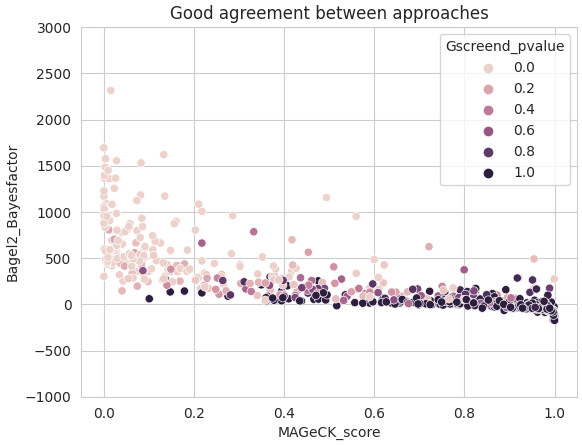

In [386]:
with sns.axes_style('whitegrid'):
    sns.scatterplot(data=gene_df, x='MAGeCK_score', y='Bagel2_Bayesfactor', hue='Gscreend_pvalue')
pl.title('Good agreement between approaches')
pl.ylim(-1000, 3000)
pl.show()

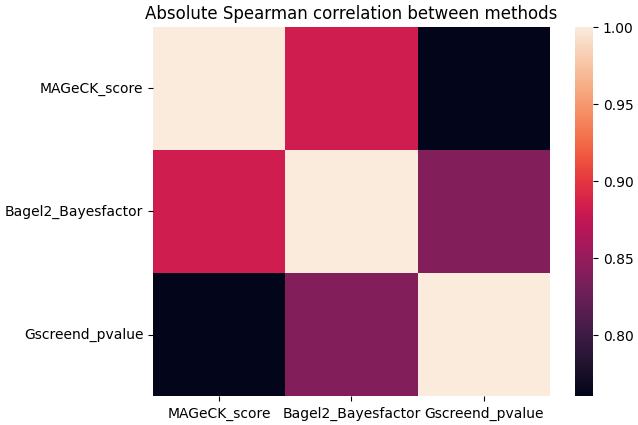

In [391]:
spearman = gene_df[['MAGeCK_score', 'Bagel2_Bayesfactor', 'Gscreend_pvalue']].corr(method='spearman').abs()
sns.heatmap(spearman, annot=False)
pl.title('Absolute Spearman correlation between methods')
pl.show()

In [394]:
# transcript-wise
transcript_df = mageck_transcript.copy()
transcript_df.to_csv('../results/merged/transcript_results.csv')

In [395]:
# guide-wise
guide_df = guide_ranking.copy()
guide_df.to_csv('../results/merged/guide_results.csv')

In [396]:
# Multi-sheet excel
with pd.ExcelWriter('../results/merged/merged_results.xlsx') as writer:
    gene_df.to_excel(writer, sheet_name='gene_results')
    transcript_df.to_excel(writer, sheet_name='transcript_results')
    guide_df.to_excel(writer, sheet_name='guide_results')